# Experiment 11: Project LAST EXIT — Intelligent Disaster Evacuation System

**Aim:** Develop an intelligent system that coordinates rescue teams and helps people evacuate safely during a disaster.

This notebook demonstrates:
1. Knowledge representation for rescue teams, affected areas, shelters, and roads.
2. IF–THEN rules using forward-chaining style reasoning.
3. Fuzzy reasoning for uncertain flood levels, road conditions, and emergency reports.
4. Resource allocation based on team capacity, shelter capacity, and route conditions.
5. Multi-agent coordination using a simplified Contract Net Protocol (CNP).
6. Scenario simulation, unexpected-event handling, visualization, and evaluation.

> **Educational simulation only:** the data and rules are synthetic. This is not a real emergency-response tool and must not be used for operational decisions.


## 1. Imports and configuration

In [1]:
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy
import random

random.seed(42)
np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Environment ready.")

Environment ready.


## 2. Knowledge representation

We model the disaster environment as entities and relationships:
- **Affected areas** have population, flood level, urgency, and a set of connecting roads.
- **Rescue teams** have location, capacity, equipment, and availability.
- **Shelters** have capacity and availability.
- **Roads** connect locations and have travel time, condition, and a blocked flag.

A graph-like representation is used: locations are nodes and roads are edges. Tables make the knowledge base easy to inspect and update.

In [2]:
areas = {
    "A1": {"name": "Riverside", "population": 120, "flood": 0.90, "urgency": 0.90, "location": "A1"},
    "A2": {"name": "Market District", "population": 80, "flood": 0.65, "urgency": 0.70, "location": "A2"},
    "A3": {"name": "Hill Colony", "population": 60, "flood": 0.30, "urgency": 0.45, "location": "A3"},
    "A4": {"name": "Old Town", "population": 100, "flood": 0.78, "urgency": 0.85, "location": "A4"},
}

teams = {
    "T1": {"name": "Alpha", "location": "BASE", "capacity": 70, "equipment": {"boat", "medical"}, "available": True},
    "T2": {"name": "Bravo", "location": "BASE", "capacity": 55, "equipment": {"boat"}, "available": True},
    "T3": {"name": "Charlie", "location": "BASE", "capacity": 45, "equipment": {"medical", "bus"}, "available": True},
}

shelters = {
    "S1": {"name": "Central School", "location": "S1", "capacity": 130, "available": True},
    "S2": {"name": "Sports Complex", "location": "S2", "capacity": 100, "available": True},
    "S3": {"name": "Hill Community Hall", "location": "S3", "capacity": 90, "available": True},
}

# Road edges are undirected; travel time is in minutes.
roads = [
    {"u": "BASE", "v": "A1", "time": 12, "condition": 0.75, "blocked": False},
    {"u": "BASE", "v": "A2", "time": 8, "condition": 0.90, "blocked": False},
    {"u": "BASE", "v": "A3", "time": 10, "condition": 0.95, "blocked": False},
    {"u": "BASE", "v": "A4", "time": 15, "condition": 0.70, "blocked": False},
    {"u": "A1", "v": "S1", "time": 10, "condition": 0.65, "blocked": False},
    {"u": "A1", "v": "S2", "time": 14, "condition": 0.80, "blocked": False},
    {"u": "A2", "v": "S1", "time": 8, "condition": 0.90, "blocked": False},
    {"u": "A2", "v": "S2", "time": 10, "condition": 0.85, "blocked": False},
    {"u": "A3", "v": "S2", "time": 9, "condition": 0.95, "blocked": False},
    {"u": "A3", "v": "S3", "time": 7, "condition": 0.90, "blocked": False},
    {"u": "A4", "v": "S1", "time": 12, "condition": 0.70, "blocked": False},
    {"u": "A4", "v": "S3", "time": 11, "condition": 0.80, "blocked": False},
]

areas_df = pd.DataFrame.from_dict(areas, orient="index").rename_axis("area_id").reset_index()
teams_df = pd.DataFrame([{"team_id": k, **v, "equipment": ", ".join(sorted(v["equipment"]))} for k, v in teams.items()])
shelters_df = pd.DataFrame([{"shelter_id": k, **v} for k, v in shelters.items()])
roads_df = pd.DataFrame(roads)
display(areas_df)
display(teams_df)
display(shelters_df)
display(roads_df)

,area_id,name,population,flood,urgency,location
0,A1,Riverside,120,0.90,0.90,A1
1,A2,Market District,80,0.65,0.70,A2
2,A3,Hill Colony,60,0.30,0.45,A3
3,A4,Old Town,100,0.78,0.85,A4


,team_id,name,location,capacity,equipment,available
0,T1,Alpha,BASE,70,"boat, medical",True
1,T2,Bravo,BASE,55,boat,True
2,T3,Charlie,BASE,45,"bus, medical",True


,shelter_id,name,location,capacity,available
0,S1,Central School,S1,130,True
1,S2,Sports Complex,S2,100,True
2,S3,Hill Community Hall,S3,90,True


,u,v,time,condition,blocked
0,BASE,A1,12,0.75,False
1,BASE,A2,8,0.90,False
2,BASE,A3,10,0.95,False
3,BASE,A4,15,0.70,False
4,A1,S1,10,0.65,False
5,A1,S2,14,0.80,False
6,A2,S1,8,0.90,False
7,A2,S2,10,0.85,False
8,A3,S2,9,0.95,False
9,A3,S3,7,0.90,False


## 3. Rule-based reasoning (forward chaining)

In [3]:
def infer_priorities(area_data):
    """Apply IF-THEN rules to derive priority and suggested action."""
    results = []
    for aid, a in area_data.items():
        facts = []
        score = 0.5 * a["urgency"] + 0.3 * a["flood"] + 0.2 * min(a["population"] / 120, 1)
        # IF flood is high THEN add an immediate evacuation fact.
        if a["flood"] >= 0.75:
            facts.append("HIGH_FLOOD")
        # IF urgency is high OR flood is high THEN priority is critical.
        if a["urgency"] >= 0.80 or a["flood"] >= 0.85:
            priority, action = "Critical", "Evacuate immediately; send rescue team"
        # IF flood is moderate THEN priority is high.
        elif a["flood"] >= 0.60 or a["urgency"] >= 0.65:
            priority, action = "High", "Prepare evacuation and monitor route"
        else:
            priority, action = "Moderate", "Monitor conditions and prepare shelter"
        if a["population"] >= 100:
            facts.append("LARGE_POPULATION")
        results.append({"area_id": aid, "area": a["name"], "priority_score": round(score, 3),
                        "priority": priority, "recommended_action": action, "inferred_facts": ", ".join(facts) or "NORMAL"})
    return pd.DataFrame(results).sort_values("priority_score", ascending=False).reset_index(drop=True)

priority_df = infer_priorities(areas)
display(priority_df)

,area_id,area,priority_score,priority,recommended_action,inferred_facts
0,A1,Riverside,0.920,Critical,Evacuate immediately; send rescue team,"HIGH_FLOOD, LARGE_POPULATION"
1,A4,Old Town,0.826,Critical,Evacuate immediately; send rescue team,"HIGH_FLOOD, LARGE_POPULATION"
2,A2,Market District,0.678,High,Prepare evacuation and monitor route,NORMAL
3,A3,Hill Colony,0.415,Moderate,Monitor conditions and prepare shelter,NORMAL


## 4. Handling uncertainty with fuzzy logic

Instead of treating flood measurements as perfectly certain, use simple membership functions:
- **Low flood:** strongest near 0
- **Medium flood:** strongest around 0.5
- **High flood:** strongest near 1

The fuzzy risk score combines flood severity, road danger, and urgency. Membership functions are intentionally simple so their behavior is transparent.

In [4]:
def triangular(x, a, b, c):
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    return (x - a) / (b - a) if x < b else (c - x) / (c - b)

def fuzzy_flood_memberships(x):
    return {
        "low": max(0.0, min(1.0, (0.55 - x) / 0.55)),
        "medium": triangular(x, 0.20, 0.50, 0.80),
        "high": max(0.0, min(1.0, (x - 0.45) / 0.55)),
    }

def fuzzy_risk(flood, urgency, road_condition):
    # Lower road condition means greater danger.
    mf = fuzzy_flood_memberships(float(np.clip(flood, 0, 1)))
    road_danger = 1 - float(np.clip(road_condition, 0, 1))
    # Transparent weighted aggregation as a compact fuzzy-inspired risk score.
    risk = 0.45 * max(mf["medium"] * 0.55, mf["high"]) + 0.35 * urgency + 0.20 * road_danger
    return round(float(np.clip(risk, 0, 1)), 3), mf

fuzzy_rows = []
for aid, a in areas.items():
    linked = [r for r in roads if r["u"] == aid or r["v"] == aid]
    avg_condition = np.mean([r["condition"] for r in linked]) if linked else 0.5
    score, memberships = fuzzy_risk(a["flood"], a["urgency"], avg_condition)
    fuzzy_rows.append({"area_id": aid, "area": a["name"], "flood": a["flood"],
                       "low_membership": round(memberships["low"], 2),
                       "medium_membership": round(memberships["medium"], 2),
                       "high_membership": round(memberships["high"], 2),
                       "avg_road_condition": round(avg_condition, 2), "fuzzy_risk": score})
fuzzy_df = pd.DataFrame(fuzzy_rows).sort_values("fuzzy_risk", ascending=False)
display(fuzzy_df)

,area_id,area,flood,low_membership,medium_membership,high_membership,avg_road_condition,fuzzy_risk
0,A1,Riverside,0.90,0.00,0.00,0.82,0.73,0.737
3,A4,Old Town,0.78,0.00,0.07,0.60,0.73,0.621
1,A2,Market District,0.65,0.00,0.50,0.36,0.88,0.432
2,A3,Hill Colony,0.30,0.45,0.33,0.00,0.93,0.253


## 5. Resource allocation and route feasibility

A candidate assignment is valid only when:
- the team and shelter are available,
- the team can carry some evacuees,
- the shelter has remaining capacity,
- the route from base to affected area and then to shelter is not blocked.

For this small demonstration, route selection uses the direct road edges in the knowledge base. The allocator prioritizes higher-risk areas and selects the feasible team/shelter combination with the lowest estimated cost.

In [5]:
def find_road(u, v, road_list):
    for r in road_list:
        if {r["u"], r["v"]} == {u, v}:
            return r
    return None

def route_cost(area_id, shelter_id, road_list):
    r1 = find_road("BASE", area_id, road_list)
    r2 = find_road(area_id, shelter_id, road_list)
    if not r1 or not r2 or r1["blocked"] or r2["blocked"]:
        return None
    # Poor road conditions increase expected travel time.
    return r1["time"] / max(r1["condition"], 0.1) + r2["time"] / max(r2["condition"], 0.1)

def allocate_resources(area_data, team_data, shelter_data, road_list, risk_table):
    remaining_population = {a: d["population"] for a, d in area_data.items()}
    remaining_capacity = {s: d["capacity"] for s, d in shelter_data.items()}
    used_teams = set()
    allocations = []
    risk_map = dict(zip(risk_table["area_id"], risk_table["fuzzy_risk"]))
    ordered_areas = sorted(area_data, key=lambda a: risk_map.get(a, 0), reverse=True)

    for aid in ordered_areas:
        if remaining_population[aid] <= 0:
            continue
        candidates = []
        for tid, t in team_data.items():
            if not t["available"] or tid in used_teams:
                continue
            for sid, s in shelter_data.items():
                if not s["available"] or remaining_capacity[sid] <= 0:
                    continue
                cost = route_cost(aid, sid, road_list)
                if cost is None:
                    continue
                load = min(remaining_population[aid], t["capacity"], remaining_capacity[sid])
                if load > 0:
                    # Small penalty for longer/less safe routes.
                    candidates.append((cost + 20 * (1 - min(r["condition"] for r in road_list
                                        if r["u"] in [aid, sid] or r["v"] in [aid, sid])), tid, sid, load, cost))
        if not candidates:
            continue
        candidates.sort(key=lambda x: x[0])
        _, tid, sid, load, cost = candidates[0]
        allocations.append({"area_id": aid, "area": area_data[aid]["name"], "team_id": tid,
                            "team": team_data[tid]["name"], "shelter_id": sid,
                            "shelter": shelter_data[sid]["name"], "people_evacuated": load,
                            "estimated_travel_minutes": round(cost, 1), "risk": risk_map.get(aid, 0)})
        remaining_population[aid] -= load
        remaining_capacity[sid] -= load
        used_teams.add(tid)

    return pd.DataFrame(allocations), remaining_population, remaining_capacity

allocations_df, remaining_people, remaining_shelter_capacity = allocate_resources(
    areas, teams, shelters, roads, fuzzy_df
)
display(allocations_df)
print("People remaining by area:", remaining_people)
print("Shelter capacity remaining:", remaining_shelter_capacity)

,area_id,area,team_id,team,shelter_id,shelter,people_evacuated,estimated_travel_minutes,risk
0,A1,Riverside,T1,Alpha,S1,Central School,70,31.4,0.737
1,A4,Old Town,T2,Bravo,S3,Hill Community Hall,55,35.2,0.621
2,A2,Market District,T3,Charlie,S2,Sports Complex,45,20.7,0.432


People remaining by area: {'A1': 50, 'A2': 35, 'A3': 60, 'A4': 45}
Shelter capacity remaining: {'S1': 60, 'S2': 55, 'S3': 35}


## 6. Multi-agent coordination: simplified Contract Net Protocol (CNP)

In the Contract Net Protocol:
1. A coordinator announces an evacuation task.
2. Available rescue teams submit bids based on capacity and travel cost.
3. The coordinator awards the task to the best feasible bid.
4. The selected team executes the task; other teams remain available for later tasks.

This simplified implementation uses the same allocation constraints but explicitly records bids and awards for one high-priority task.

In [6]:
def contract_net(task_area, area_data, team_data, shelter_data, road_list):
    bids = []
    for tid, team in team_data.items():
        if not team["available"]:
            continue
        best_shelter = None
        best_cost = float("inf")
        for sid, shelter in shelter_data.items():
            if not shelter["available"] or shelter["capacity"] <= 0:
                continue
            cost = route_cost(task_area, sid, road_list)
            if cost is not None and cost < best_cost:
                best_cost, best_shelter = cost, sid
        if best_shelter is not None:
            bid_capacity = min(team["capacity"], area_data[task_area]["population"], shelter_data[best_shelter]["capacity"])
            # Lower bid score is preferred; travel time matters, while higher capacity is beneficial.
            bid_score = best_cost - 0.08 * bid_capacity
            bids.append({"team_id": tid, "team": team["name"], "shelter_id": best_shelter,
                         "shelter": shelter_data[best_shelter]["name"], "capacity_offer": bid_capacity,
                         "estimated_time": round(best_cost, 1), "bid_score": round(bid_score, 2)})
    bids_df = pd.DataFrame(bids).sort_values("bid_score").reset_index(drop=True) if bids else pd.DataFrame()
    award = bids_df.iloc[0].to_dict() if not bids_df.empty else None
    return bids_df, award

highest_priority_area = priority_df.iloc[0]["area_id"]
bids_df, award = contract_net(highest_priority_area, areas, teams, shelters, roads)
print(f"Task announced for {highest_priority_area} — {areas[highest_priority_area]['name']}")
display(bids_df)
print("Awarded contract:", award)

Task announced for A1 — Riverside


,team_id,team,shelter_id,shelter,capacity_offer,estimated_time,bid_score
0,T1,Alpha,S1,Central School,70,31.4,25.78
1,T2,Bravo,S1,Central School,55,31.4,26.98
2,T3,Charlie,S1,Central School,45,31.4,27.78


Awarded contract: {'team_id': 'T1', 'team': 'Alpha', 'shelter_id': 'S1', 'shelter': 'Central School', 'capacity_offer': 70, 'estimated_time': 31.4, 'bid_score': 25.78}


## 7. Simulation and unexpected-event adaptation

We compare:
- **Baseline:** all roads and shelters initially available.
- **Disruption:** a key road is blocked and one shelter becomes unavailable.

The system recalculates feasible allocations after the event. This illustrates replanning rather than assuming the original plan remains valid.

In [7]:
def run_scenario(name, area_data, team_data, shelter_data, road_list):
    risk_rows = []
    for aid, a in area_data.items():
        connected = [r for r in road_list if r["u"] == aid or r["v"] == aid]
        safe_conditions = [r["condition"] for r in connected if not r["blocked"]]
        avg_condition = np.mean(safe_conditions) if safe_conditions else 0.1
        risk, _ = fuzzy_risk(a["flood"], a["urgency"], avg_condition)
        risk_rows.append({"area_id": aid, "fuzzy_risk": risk})
    risk_table = pd.DataFrame(risk_rows)
    alloc, remaining, capacity = allocate_resources(area_data, team_data, shelter_data, road_list, risk_table)
    evacuated = int(alloc["people_evacuated"].sum()) if not alloc.empty else 0
    total_population = sum(a["population"] for a in area_data.values())
    avg_time = float(alloc["estimated_travel_minutes"].mean()) if not alloc.empty else np.nan
    # Resource usage is the count of teams assigned.
    teams_used = int(alloc["team_id"].nunique()) if not alloc.empty else 0
    metrics = {"scenario": name, "total_population": total_population, "people_evacuated": evacuated,
               "people_not_evacuated": total_population - evacuated,
               "evacuation_rate_pct": round(100 * evacuated / total_population, 1),
               "teams_used": teams_used, "mean_estimated_travel_minutes": round(avg_time, 1) if not np.isnan(avg_time) else np.nan}
    return alloc, metrics

base_areas = copy.deepcopy(areas)
base_teams = copy.deepcopy(teams)
base_shelters = copy.deepcopy(shelters)
base_roads = copy.deepcopy(roads)

baseline_alloc, baseline_metrics = run_scenario("Baseline", base_areas, base_teams, base_shelters, base_roads)

disrupted_areas = copy.deepcopy(areas)
disrupted_teams = copy.deepcopy(teams)
disrupted_shelters = copy.deepcopy(shelters)
disrupted_roads = copy.deepcopy(roads)

# Unexpected event 1: road between A1 and S1 is blocked.
for r in disrupted_roads:
    if {r["u"], r["v"]} == {"A1", "S1"}:
        r["blocked"] = True
# Unexpected event 2: S2 is temporarily unavailable.
disrupted_shelters["S2"]["available"] = False

disrupted_alloc, disrupted_metrics = run_scenario("Blocked road + S2 unavailable",
                                                   disrupted_areas, disrupted_teams,
                                                   disrupted_shelters, disrupted_roads)

comparison_df = pd.DataFrame([baseline_metrics, disrupted_metrics])
display(comparison_df)
print("\nBaseline allocations")
display(baseline_alloc)
print("\nDisrupted allocations after replanning")
display(disrupted_alloc)

,scenario,total_population,people_evacuated,people_not_evacuated,evacuation_rate_pct,teams_used,mean_estimated_travel_minutes
0,Baseline,360,170,190,47.2,3,29.1
1,Blocked road + S2 unavailable,360,145,215,40.3,3,23.8



Baseline allocations


,area_id,area,team_id,team,shelter_id,shelter,people_evacuated,estimated_travel_minutes,risk
0,A1,Riverside,T1,Alpha,S1,Central School,70,31.4,0.737
1,A4,Old Town,T2,Bravo,S3,Hill Community Hall,55,35.2,0.621
2,A2,Market District,T3,Charlie,S2,Sports Complex,45,20.7,0.432



Disrupted allocations after replanning


,area_id,area,team_id,team,shelter_id,shelter,people_evacuated,estimated_travel_minutes,risk
0,A4,Old Town,T1,Alpha,S3,Hill Community Hall,70,35.2,0.621
1,A2,Market District,T2,Bravo,S1,Central School,55,17.8,0.432
2,A3,Hill Colony,T3,Charlie,S3,Hill Community Hall,20,18.3,0.253


## 8. Visualize and compare outcomes

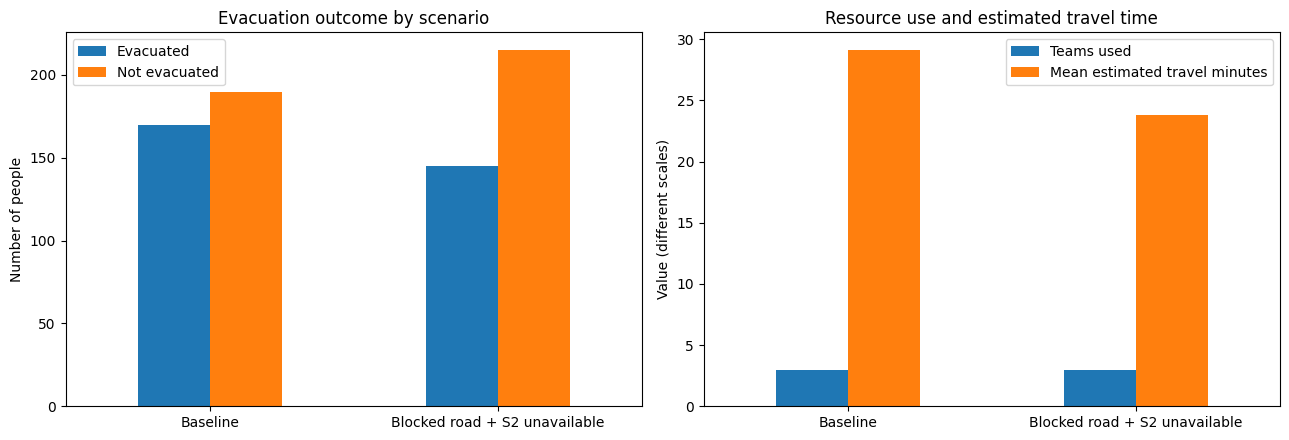

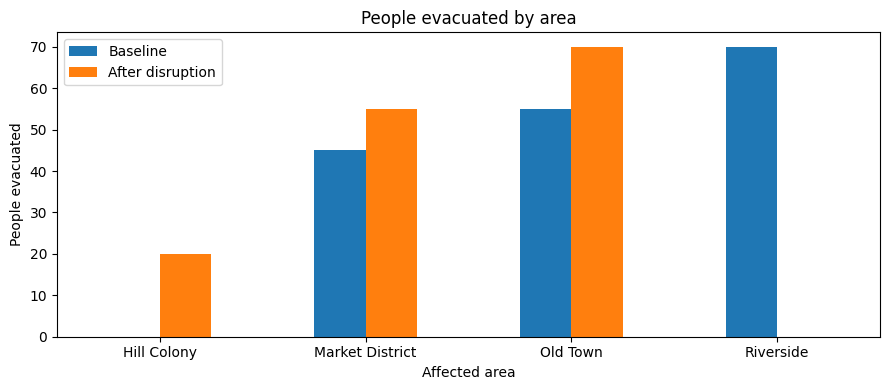

,Baseline,After disruption
area,,
Hill Colony,0.0,20.0
Market District,45.0,55.0
Old Town,55.0,70.0
Riverside,70.0,0.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

comparison_df.set_index("scenario")[["people_evacuated", "people_not_evacuated"]].plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Evacuation outcome by scenario")
axes[0].set_ylabel("Number of people")
axes[0].set_xlabel("")
axes[0].legend(["Evacuated", "Not evacuated"])

comparison_df.set_index("scenario")[["teams_used", "mean_estimated_travel_minutes"]].plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_title("Resource use and estimated travel time")
axes[1].set_ylabel("Value (different scales)")
axes[1].set_xlabel("")
axes[1].legend(["Teams used", "Mean estimated travel minutes"])

plt.tight_layout()
plt.show()

# Allocation volume by affected area
if not baseline_alloc.empty or not disrupted_alloc.empty:
    b = baseline_alloc.groupby("area")["people_evacuated"].sum() if not baseline_alloc.empty else pd.Series(dtype=float)
    d = disrupted_alloc.groupby("area")["people_evacuated"].sum() if not disrupted_alloc.empty else pd.Series(dtype=float)
    area_compare = pd.DataFrame({"Baseline": b, "After disruption": d}).fillna(0)
    area_compare.plot(kind="bar", figsize=(9, 4), rot=0)
    plt.title("People evacuated by area")
    plt.ylabel("People evacuated")
    plt.xlabel("Affected area")
    plt.tight_layout()
    plt.show()
    display(area_compare)

## 9. Evaluation and observations

The metrics are:
- **People evacuated safely:** total assigned to feasible team–shelter plans.
- **Evacuation rate:** evacuated people divided by total affected population.
- **Resource usage:** number of distinct rescue teams assigned.
- **Estimated travel time:** mean cost-adjusted travel time of assignments.

Interpretation:
- A blocked road or unavailable shelter may reduce the number of feasible assignments.
- Replanning can redirect teams to alternate shelters when a feasible route exists.
- The greedy allocator is a teaching baseline, not a globally optimal solver. It does not model detailed road-network shortest paths, team return journeys, medical triage, time windows, or dynamic traffic.
- For real deployments, decisions require verified live data, emergency-service oversight, robust optimization, and safety validation.

In [9]:
print("FINAL SUMMARY")
for _, row in comparison_df.iterrows():
    print(f"\n{row['scenario']}")
    print(f"  Evacuated: {int(row['people_evacuated'])}/{int(row['total_population'])} "
          f"({row['evacuation_rate_pct']}%)")
    print(f"  Not evacuated: {int(row['people_not_evacuated'])}")
    print(f"  Teams used: {int(row['teams_used'])}")
    print(f"  Mean estimated travel time: {row['mean_estimated_travel_minutes']} minutes")

print("\nExperiment completed. All scenarios use synthetic data for educational demonstration.")

FINAL SUMMARY

Baseline
  Evacuated: 170/360 (47.2%)
  Not evacuated: 190
  Teams used: 3
  Mean estimated travel time: 29.1 minutes

Blocked road + S2 unavailable
  Evacuated: 145/360 (40.3%)
  Not evacuated: 215
  Teams used: 3
  Mean estimated travel time: 23.8 minutes

Experiment completed. All scenarios use synthetic data for educational demonstration.
